# # 07 · Mixture of Experts (Mixtral, DeepSeek-MoE, Qwen-MoE, Switch)
#
# Replace the dense MLP of each block by **E parallel expert MLPs** plus a tiny **router**. Each token is sent to only its
# top-k experts, so *total* parameters (capacity) grow without growing *active* parameters (FLOPs per token).
#
# `y = Σ_{e ∈ topk(router(x))} w_e · Expert_e(x)`   (+ optional always-on **shared expert**, as in DeepSeek)
#
# A **load-balancing auxiliary loss** stops the router from collapsing onto a single expert.

In [1]:
import torch, torch.nn as nn, torch.nn.functional as F, matplotlib.pyplot as plt, numpy as np, pandas as pd, seaborn as sns
from llmarch import *
from llmarch.blocks import *
set_seed(0); device = get_device(); STEPS = 1200
data = load_text_data("char"); train, val, V = data["train"], data["val"], data["vocab_size"]

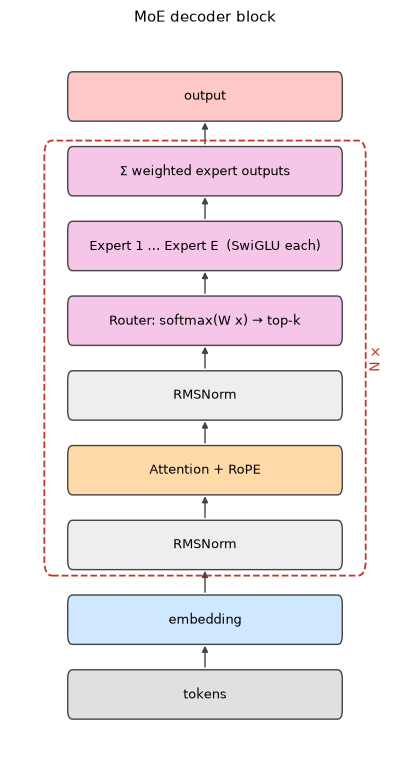

In [2]:
block_diagram([("output", "out"), ("Σ weighted expert outputs", "moe*"), ("Expert 1 … Expert E  (SwiGLU each)", "moe*"), ("Router: softmax(W x) → top-k", "moe*"),
               ("RMSNorm", "norm*"), ("Attention + RoPE", "attn*"), ("RMSNorm", "norm*"), ("embedding", "embed"), ("tokens", "other")][::-1], title="MoE decoder block", repeat="N ×")

# ## The MoE layer

In [3]:
show_source(MoE)

```python
class MoE(nn.Module):
    """Token-choice top-k routing over `n_exp` SwiGLU experts (+ optional always-on shared expert).
    forward returns (y, aux) where aux is the Switch-style load-balancing loss."""
    def __init__(self, d, n_exp=4, top_k=1, hidden=None, shared=False, aux_coef=0.01):
        super().__init__()
        self.n_exp, self.top_k, self.aux_coef = n_exp, top_k, aux_coef
        self.router = nn.Linear(d, n_exp, bias=False)
        self.experts = nn.ModuleList([SwiGLU(d, hidden) for _ in range(n_exp)])
        self.shared = SwiGLU(d, hidden) if shared else None
        self.last_probs = None; self.last_idx = None

    def forward(self, x):
        B, T, D = x.shape; xf = x.reshape(-1, D)
        probs = self.router(xf).softmax(-1)                               # (N, E)
        w, idx = probs.topk(self.top_k, dim=-1); w = w / w.sum(-1, keepdim=True)
        out = torch.zeros_like(xf)
        for e, expert in enumerate(self.experts):
            tok, slot = (idx == e).nonzero(as_tuple=True)
            if tok.numel():
                out[tok] += w[tok, slot, None] * expert(xf[tok])
        if self.shared is not None:
            out = out + self.shared(xf)
        frac = F.one_hot(idx[:, 0], self.n_exp).float().mean(0)           # fraction routed (top-1)
        aux = self.aux_coef * self.n_exp * (frac * probs.mean(0)).sum()
        self.last_probs, self.last_idx = probs.detach().view(B, T, -1), idx.detach().view(B, T, -1)
        return out.view(B, T, D), aux

```

# ## Dense vs MoE at equal *active* parameters
# Dense MLP hidden size 170 vs. 8 experts of hidden 21 with top-2... we instead keep expert size equal to the dense MLP and
# pick top-1 (Switch-style, same FLOPs per token) or top-2 with half-size experts (Mixtral-style, same FLOPs).

In [4]:
d, H, NL = 96, 4, 3
def build(ffn, aux=False):
    return DecoderLM(V, d, [Block(d, Attention(d, H, rope=True, bias=False), ffn()) for _ in range(NL)], has_aux=aux)
configs = {
    "Dense SwiGLU (h=256)":                 (lambda: SwiGLU(d, 256), False),
    "MoE 8e top-1 (h=256, Switch)":         (lambda: MoE(d, 8, 1, hidden=256), True),
    "MoE 8e top-2 (h=128, Mixtral)":        (lambda: MoE(d, 8, 2, hidden=128), True),
    "MoE 8e top-2 + shared (h=96, DeepSeek)": (lambda: MoE(d, 8, 2, hidden=96, shared=True), True),
}
models, hists = {}, {}
for name, (ffn, aux) in configs.items():
    set_seed(0); models[name] = build(ffn, aux); print("==", name, f"| total params {count_params(models[name]):,}")
    hists[name] = train_lm(models[name], train, val, steps=STEPS, block_size=64, batch_size=32, lr=3e-3, device=device, eval_every=300, verbose=False)
def active_params(m):
    tot = count_params(m)
    for b in m.blocks:
        if isinstance(b.ffn, MoE):
            e = sum(p.numel() for p in b.ffn.experts[0].parameters()); tot -= e * (b.ffn.n_exp - b.ffn.top_k)
    return tot
df = pd.DataFrame({n: dict(total_params=count_params(m), active_params=active_params(m), val_loss=hists[n]["val"][-1]) for n, m in models.items()}).T; df

== Dense SwiGLU (h=256) | total params 338,688


== MoE 8e top-1 (h=256, Switch) | total params 1,889,280


== MoE 8e top-2 (h=128, Mixtral) | total params 1,004,544


== MoE 8e top-2 + shared (h=96, DeepSeek) | total params 866,304


,total_params,active_params,val_loss
Dense SwiGLU (h=256),338688.0,338688.0,1.658556
"MoE 8e top-1 (h=256, Switch)",1889280.0,340992.0,1.790876
"MoE 8e top-2 (h=128, Mixtral)",1004544.0,340992.0,1.653195
"MoE 8e top-2 + shared (h=96, DeepSeek)",866304.0,368640.0,1.637120


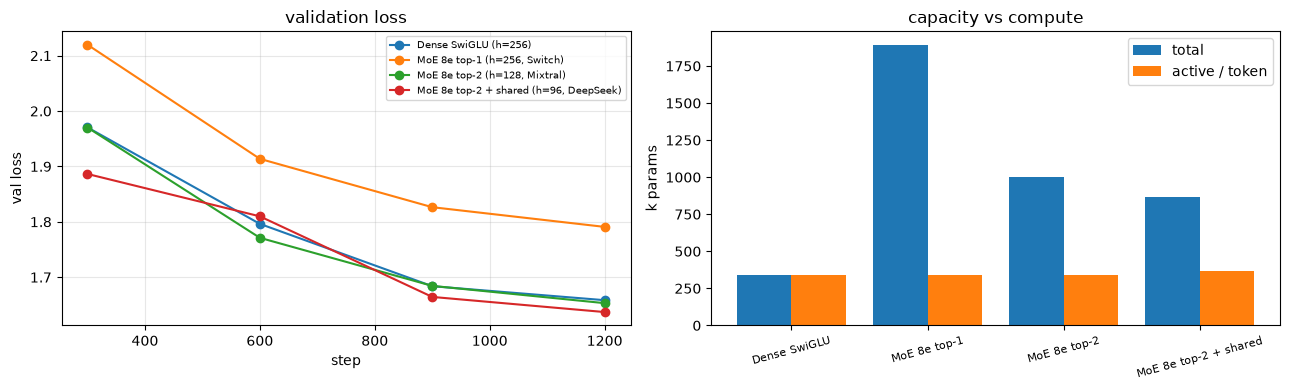

In [5]:
save_result("07 MoE (8 experts top-2, Mixtral-style)", models["MoE 8e top-2 (h=128, Mixtral)"], hists["MoE 8e top-2 (h=128, Mixtral)"],
            extra={"active_params": active_params(models["MoE 8e top-2 (h=128, Mixtral)"])})
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, h in hists.items(): ax[0].plot(h["val_step"], h["val"], "o-", label=n)
ax[0].set(xlabel="step", ylabel="val loss", title="validation loss"); ax[0].legend(fontsize=7); ax[0].grid(alpha=.3)
x = np.arange(len(df)); ax[1].bar(x - .2, df.total_params / 1e3, .4, label="total"); ax[1].bar(x + .2, df.active_params / 1e3, .4, label="active / token")
ax[1].set_xticks(x); ax[1].set_xticklabels([n.split(" (")[0] for n in df.index], rotation=15, fontsize=8); ax[1].set_ylabel("k params"); ax[1].legend(); ax[1].set_title("capacity vs compute")
plt.tight_layout(); plt.show()

# ## What did the router learn?
# Run text through the Mixtral-style model and record, for every layer, which experts each character is sent to.

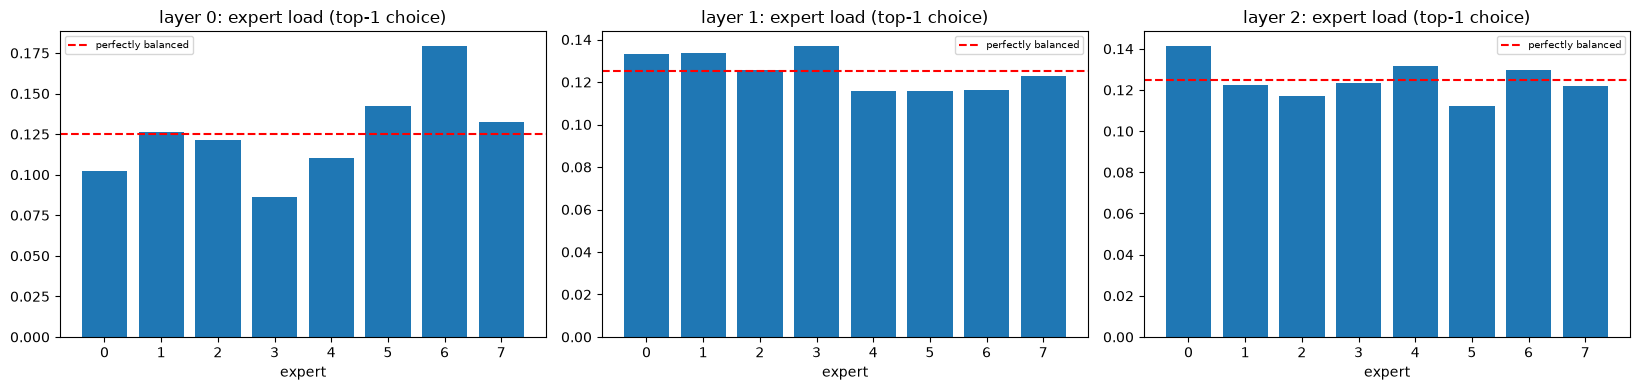

In [6]:
m = models["MoE 8e top-2 (h=128, Mixtral)"].eval()
xs = torch.stack([val[i:i + 64] for i in range(0, 64 * 100, 64)]).to(device)
with torch.no_grad(): m(xs)
chars = np.array([data["itos"][i] for i in xs.reshape(-1).cpu().tolist()])
fig, axs = plt.subplots(1, NL, figsize=(5.5 * NL, 4))
for l, ax in enumerate(axs):
    idx = m.blocks[l].ffn.last_idx[..., 0].reshape(-1).cpu()          # first-choice expert per token
    load = torch.bincount(idx, minlength=8).float(); ax.bar(range(8), load / load.sum()); ax.axhline(1 / 8, color="r", ls="--", label="perfectly balanced")
    ax.set(title=f"layer {l}: expert load (top-1 choice)", xlabel="expert"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

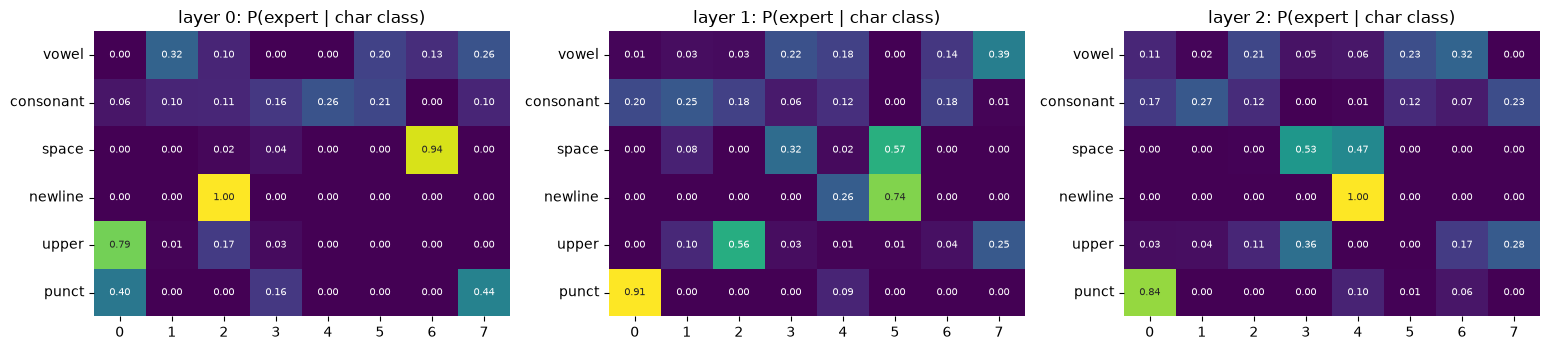

In [7]:
groups = {"vowel": list("aeiou"), "consonant": list("bcdfghjklmnpqrstvwxyz"), "space": [" "], "newline": ["\n"], "upper": list("ABCDEFGHIJKLMNOPQRSTUVWXYZ"), "punct": list(",.;:!?'-")}
fig, axs = plt.subplots(1, NL, figsize=(5.2 * NL, 3.6))
for l, ax in enumerate(axs):
    idx = m.blocks[l].ffn.last_idx[..., 0].reshape(-1).cpu().numpy(); M = np.zeros((len(groups), 8))
    for gi, (g, cs) in enumerate(groups.items()):
        sel = np.isin(chars, cs); M[gi] = np.bincount(idx[sel], minlength=8) / max(sel.sum(), 1)
    sns.heatmap(M, ax=ax, annot=True, fmt=".2f", cmap="viridis", xticklabels=range(8), yticklabels=list(groups), cbar=False, annot_kws={"size": 7}); ax.set_title(f"layer {l}: P(expert | char class)")
plt.tight_layout(); plt.show()

# ### Routing over a sentence (layer 0)
# Colour = first-choice expert for every character.

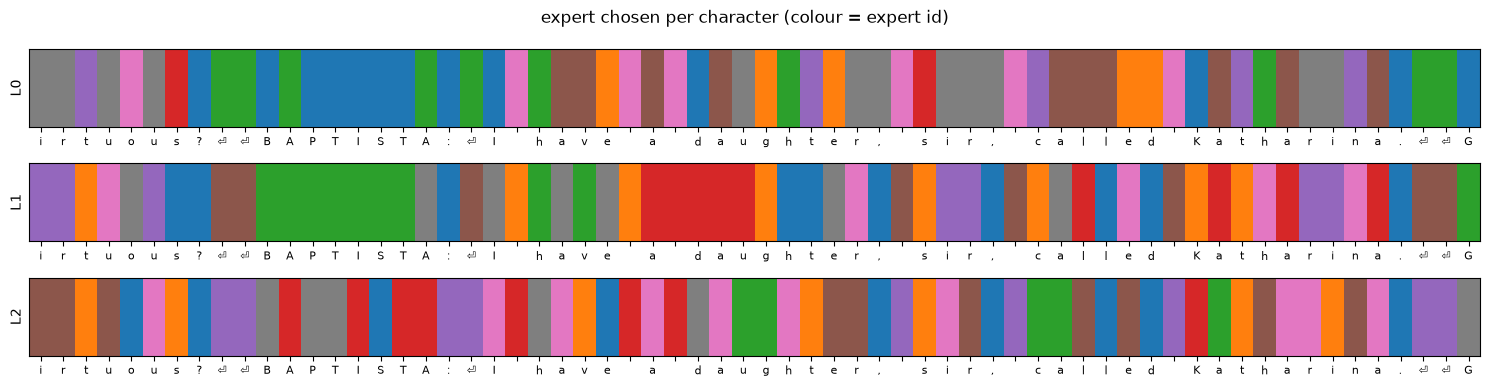

In [8]:
seq = val[200:264]; seq_chars = [("⏎" if c == "\n" else c) for c in data["decode"](seq.tolist())]
with torch.no_grad(): m(seq[None].to(device))
fig, axs = plt.subplots(NL, 1, figsize=(15, 1.3 * NL))
for l, ax in enumerate(axs):
    e = m.blocks[l].ffn.last_idx[0, :, 0].cpu().numpy(); ax.imshow(e[None], cmap="tab10", vmin=0, vmax=9, aspect="auto")
    ax.set_xticks(range(64)); ax.set_xticklabels(seq_chars, fontsize=8); ax.set_yticks([]); ax.set_ylabel(f"L{l}")
plt.suptitle("expert chosen per character (colour = expert id)"); plt.tight_layout(); plt.show()